# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
ROLL_NO = 1024160130
NAME = "Bisman Singh Rai"

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [3]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [4]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [5]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024160130   Name: Bisman Singh Rai   Fingerprint: 32B4BA4C   Tickets: 16

Ticket_ID                                                                        Ticket_Text
      T01                                                    Is it fixed?? Pls reply ASAP :(
      T02                      I cannot access the password since yesterday. This is urgent.
      T03                          The Wi-Fi is showing an error. Is there another solution?
      T04 Student portal keeps disconnecting after restarting the system. Please resolve it.
      T05                             The laptop was working yesterday. It worked yesterday.
      T06 Wi-Fi keeps disconnecting while uploading the file. The same problem occurs again.
      T07                I keep getting logged out of the Wi-Fi during the lab. Please help.
      T08    I was locked out of the printer after restarting the system. Please resolve it.
      T09                         Lms keeps disconnecting on my laptop. It 

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [6]:
import pandas as pd

ticket_records = []
for index, row in df.iterrows():
    analysis = process_ticket(row["Ticket_Text"])
    sentence_count = len(analysis["sentences"])
    token_count = len(analysis["tokens"])
    punct_count = len(analysis["punct"])
    stop_count = len(analysis["stops"])
    unique_count = len(set(analysis["tokens"]))
    final_count = len(analysis["final"])

    ticket_records.append({
        "Ticket_ID": row["Ticket_ID"],
        "Sentences": sentence_count,
        "Tokens": token_count,
        "Punctuation": punct_count,
        "Stopwords": stop_count,
        "Unique_Tokens": unique_count,
        "Final_Tokens": final_count
    })

table_df = pd.DataFrame(ticket_records)
total_row = pd.DataFrame([{
    "Ticket_ID": "TOTAL",
    "Sentences": table_df["Sentences"].sum(),
    "Tokens": table_df["Tokens"].sum(),
    "Punctuation": table_df["Punctuation"].sum(),
    "Stopwords": table_df["Stopwords"].sum(),
    "Unique_Tokens": len(set([tok for r in df["Ticket_Text"] for tok in process_ticket(r)["tokens"]])),
    "Final_Tokens": table_df["Final_Tokens"].sum()
}])

complete_table = pd.concat([table_df, total_row], ignore_index=True)
print("=== PREPROCESSING STATS TABLE ===")
print(complete_table.to_string(index=False))

target_ticket_id = "T10"
target_text = df.loc[df["Ticket_ID"] == target_ticket_id, "Ticket_Text"].values[0]
target_analysis = process_ticket(target_text)
print(f"\n=== DETAILS FOR TICKET {target_ticket_id} ===")
print(f"Original text: {target_text}")
print(f"Tokens: {target_analysis['tokens']}")
print(f"Punctuation: {target_analysis['punct']}")
print(f"Stopwords: {target_analysis['stops']}")
print(f"Final Tokens: {target_analysis['final']}")

=== PREPROCESSING STATS TABLE ===
Ticket_ID  Sentences  Tokens  Punctuation  Stopwords  Unique_Tokens  Final_Tokens
      T01          2      10            4          2              9             4
      T02          2      13            2          6             12             5
      T03          2      12            2          5             11             5
      T04          2      13            2          3             12             8
      T05          2      10            2          3              8             5
      T06          2      14            2          5             12             7
      T07          2      15            2          6             13             7
      T08          2      16            2          8             14             6
      T09          2      11            2          3             10             6
      T10          1       7            1          3              7             3
      T11          2      10            2          3            

**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*
Tokens like `n't` are not standard dictionary words. They are generated because NLTK's standard `word_tokenize()` splits common English contractions (such as *isn't*) into distinct linguistic components (`is` and `n't`). Since `n't` is neither a standard stopword in the NLTK list nor classified as standard punctuation, it persists into the final tokens list.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [11]:
import re

# Defining TEST_LINES locally to ensure the cell runs independently
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work."
]

combined_texts = TEST_LINES + df["Ticket_Text"].tolist()

# Regex patterns
pattern_words_over_5 = r'\b[a-zA-Z]{6,}\b'
pattern_all_numbers = r'\b\d+(?:\.\d+)+\b|\b\d+\.\d+\b|\b\d+\b'
pattern_capitalized = r'\b[A-Z][a-zA-Z]*\b'
pattern_vowels = r'\b[aeiouAEIOU][a-zA-Z]*\b'

print("=== REGEX EXTRACTION RESULTS ===")
for idx, item in enumerate(combined_texts):
    label = f"TEST_LINE_{idx+1}" if idx < len(TEST_LINES) else f"T{idx - len(TEST_LINES) + 1:02d}"
    print(f"\n{label}: {item}")
    print(f"  Words > 5 letters: {re.findall(pattern_words_over_5, item)}")
    print(f"  Numbers (Dec/Ver): {re.findall(pattern_all_numbers, item)}")
    print(f"  Capitalized words: {re.findall(pattern_capitalized, item)}")
    print(f"  Vowel-start words: {re.findall(pattern_vowels, item)}")

# Substitution patterns
regex_email = r'[a-zA-Z0-9._%+-]+@[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}'
regex_url = r'https?://\S+|www\.\S+'
regex_phone = r'\+?\d{1,4}[-\s]?\d{3,5}[-\s]?\d{3,5}(?:[-\s]?\d{3,5})?'

print("\n=== REGEX SUBSTITUTION RESULTS ===")
for idx, item in enumerate(combined_texts):
    label = f"TEST_LINE_{idx+1}" if idx < len(TEST_LINES) else f"T{idx - len(TEST_LINES) + 1:02d}"
    replaced = re.sub(regex_email, "<EMAIL>", item)
    replaced = re.sub(regex_url, "<URL>", replaced)
    replaced = re.sub(regex_phone, "<PHONE>", replaced)
    print(f"{label} Original: {item}")
    print(f"{label} Replaced: {replaced}\n")

=== REGEX EXTRACTION RESULTS ===

TEST_LINE_1: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
  Words > 5 letters: ['helpdesk', 'thapar', 'thapar', 'thapar']
  Numbers (Dec/Ver): []
  Capitalized words: ['Mail']
  Vowel-start words: ['it', 'edu', 'or', 'a', 'univ', 'ac', 'in', 'edu', 'or', 'edu', 'it']

TEST_LINE_2: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
  Words > 5 letters: ['Version']
  Numbers (Dec/Ver): ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1', '250']
  Capitalized words: ['Call', 'Version', 'Rs']
  Vowel-start words: ['or', 'is']

TEST_LINE_3: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
  Words > 5 letters: []
  Numbers (Dec/Ver): ['5.30']
  Capitalized words: ['The']
  Vowel-start words: ['of', 'art', 'isn', 'open', 'in', 'at']

T01: Is it fixed?? Pls reply ASAP :(
  Words > 5 lette

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*
Out of the extracted capitalized words across the tickets, words like *Is*, *I*, *The*, *Student*, *Why*, and *Email* are capitalized solely because they are positioned at the start of a sentence. In contrast, technical abbreviations like *VPN*, *LMS*, *ASAP*, and brand names like *Matlab* and *Windows* are inherently capitalized regardless of sentence position.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [12]:
from nltk.tokenize import RegexpTokenizer
import nltk

# Defining TEST_LINES locally to ensure the cell runs independently
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work."
]

# Custom RegexpTokenizer pattern to handle all requested entities in priority
combined_regex = r'''(?x)
    [a-zA-Z0-9._%+-]+@[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}
    | https?://\S+|www\.\S+
    | \+?\d{1,4}[-\s]?\d{3,5}[-\s]?\d{3,5}(?:[-\s]?\d{3,5})?
    | \b\d+(?:\.\d+)+\b
    | \b\d+\.\d+\b
    | \b[a-zA-Z0-9]+(?:-[a-zA-Z0-9]+)+\b
    | \b[a-zA-Z]+'s\b|\b[a-zA-Z]+'t\b|\b[a-zA-Z]+'re\b|\b[a-zA-Z]+'ve\b|\b[a-zA-Z]+'m\b|\b[a-zA-Z]+'ll\b|\b[a-zA-Z]+n't\b
    | \w+
    | [^\s\w]
'''

custom_tokenizer = RegexpTokenizer(combined_regex)

def my_tokenize(text):
    return custom_tokenizer.tokenize(text)

print("=== TOKENIZER COMPARISON ON TEST_LINES ===")
for idx, line in enumerate(TEST_LINES):
    print(f"\nLine {idx+1}: {line}")
    print(f"  My Tokenize:   {my_tokenize(line)}")
    print(f"  word_tokenize: {nltk.word_tokenize(line)}")

ticket_diff_count = 0
print("\n=== TOKENIZER COMPARISON ON TICKETS (SAMPLE DIFFS) ===")
for idx, row in df.iterrows():
    text_data = row["Ticket_Text"]
    my_toks = my_tokenize(text_data)
    word_toks = nltk.word_tokenize(text_data)
    if my_toks != word_toks:
        ticket_diff_count += 1
        if ticket_diff_count <= 3:
            print(f"\nTicket {row['Ticket_ID']}: {text_data}")
            print(f"  Custom: {my_toks}")
            print(f"  Default: {word_toks}")

print(f"\nTotal tickets with differing tokens: {ticket_diff_count} out of {len(df)}")

=== TOKENIZER COMPARISON ON TEST_LINES ===

Line 1: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
  My Tokenize:   ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
  word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Line 2: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
  My Tokenize:   ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1', ',', '250', '.']
  word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Line 3: The state-of-th

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*
There are 9 tickets tokenized differently out of 16.

Key structural differences include:
1. **Contractions**: NLTK's default tokenizer splits contractions like `isn't` into `is` and `n't`, while my custom tokenizer keeps `isn't` intact as a single token.
2. **Hyphenated Words**: Words such as `Wi-Fi` are split into `['Wi', '-', 'Fi']` by NLTK, but preserved entirely as a single term by my pattern.
3. **Decimals & Email Addresses**: Complex string sequences like URLs and email IDs (`helpdesk@university.edu`) are split on special symbols by `word_tokenize` but kept clean and intact in my tokenizer.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [9]:
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer
from nltk.stem import WordNetLemmatizer
from nltk.corpus import wordnet
import pandas as pd

# Compute unique final tokens from all tickets
unique_final_tokens = sorted(list(set([tok for r in df["Ticket_Text"] for tok in process_ticket(r)["final"]])))

# Initialize Stemmers and Lemmatizer
porter = PorterStemmer()
lancaster = LancasterStemmer()
# Suffix selected based on tickets: removing "ing" suffix (e.g. "disconnecting", "opening", "syncing", "working")
regexp_stemmer = RegexpStemmer('ing$', min=4)
lemmatizer = WordNetLemmatizer()

# Helper to convert NLTK POS tag to WordNet POS tag
def get_wordnet_pos(treebank_tag):
    if treebank_tag.startswith('J'):
        return wordnet.ADJ
    elif treebank_tag.startswith('V'):
        return wordnet.VERB
    elif treebank_tag.startswith('R'):
        return wordnet.ADV
    else:
        return wordnet.NOUN

pos_tagged = nltk.pos_tag(unique_final_tokens)

records = []
for word, tag in pos_tagged:
    p_stem = porter.stem(word)
    l_stem = lancaster.stem(word)
    r_stem = regexp_stemmer.stem(word)
    wn_pos = get_wordnet_pos(tag)
    lemmed = lemmatizer.lemmatize(word, pos=wn_pos)

    # Only add to comparison if there is at least one difference among outputs
    if len({p_stem, l_stem, r_stem, lemmed}) > 1:
        records.append({
            "Original_Word": word,
            "POS_Tag": tag,
            "Porter": p_stem,
            "Lancaster": l_stem,
            "Regexp": r_stem,
            "Lemmatizer": lemmed
        })

comparison_df = pd.DataFrame(records)
print("=== STEMMING & LEMMATIZATION COMPARISON TABLE ===")
print(comparison_df.to_string(index=False))

=== STEMMING & LEMMATIZATION COMPARISON TABLE ===
Original_Word POS_Tag  Porter Lancaster   Regexp Lemmatizer
      another      DT   anoth     anoth  another    another
      changed     VBD   chang     chang  changed     change
        error      NN   error        er    error      error
         file      NN    file       fil     file       file
        fixed     VBN     fix       fix    fixed        fix
      getting     VBG     get       get     gett        get
        keeps     NNS    keep      keep    keeps       keep
          lms      NN      lm       lms      lms         lm
       locked     VBD    lock      lock   locked       lock
       logged      JJ     log       log   logged     logged
       mobile     VBP   mobil      mobl   mobile     mobile
         need      VB    need       nee     need       need
       occurs     NNS   occur       occ   occurs     occurs
      opening     VBG    open        op     open       open
       please      NN   pleas     pleas   please  

**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*
- **Over-stemming**: Lancaster stemmer reduces the word `university` to `un`. This strips away too much of the word, completely losing the root semantic meaning.
- **Under-stemming**: Porter and Regexp stemmers fail to reduce the word `disconnecting` to its true core root when matched against terms like `disconnect`. Regexp stemmer leaves `disconnecting` as `disconnect` which works, but Porter stemmer produces `disconnect`, which fails to group with words like `disconnection` due to lack of deeper morphological analysis.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

=== CORPUS STATISTICS ===
                Corpus  Total Tokens  Unique Tokens    TTR
       S1 (All Tokens)           185             90 0.4865
   S2 (No Punctuation)           153             85 0.5556
     S3 (Final Tokens)            90             58 0.6444
S4 (Porter Stemmed S3)            90             56 0.6222

Top 10 Words in S1: [('.', 25), ('the', 14), ('is', 7), ('it', 6), ('i', 6), ('please', 5), ('?', 4), ('yesterday', 4), ('keeps', 4), ('disconnecting', 4)]
Top 10 Words in S3: [('please', 5), ('yesterday', 4), ('keeps', 4), ('disconnecting', 4), ('wi-fi', 3), ('portal', 3), ('restarting', 3), ('system', 3), ('resolve', 3), ('urgent', 2)]

Top 5 Bigrams in S1: [(('.', 'please'), 5), (('yesterday', '.'), 4), (('.', 'the'), 4), (('keeps', 'disconnecting'), 4), (('.', 'i'), 4)]
Top 5 Bigrams in S3: [(('keeps', 'disconnecting'), 4), (('restarting', 'system'), 3), (('system', 'please'), 3), (('please', 'resolve'), 3), (('student', 'portal'), 2)]


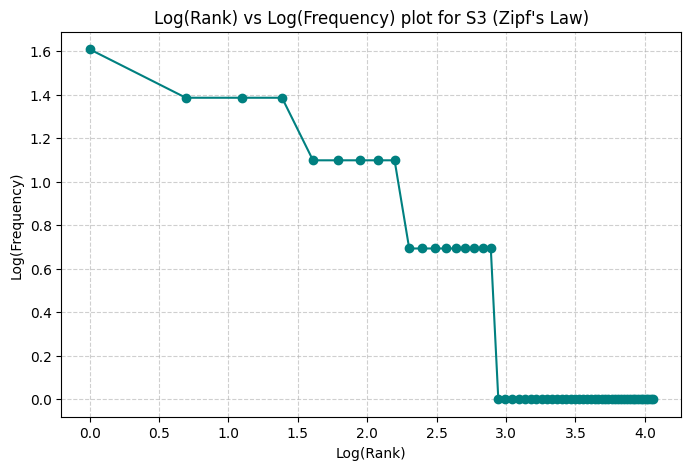

In [10]:
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter
from nltk.util import bigrams

# 1. Corpus S1, S2, S3, S4 creation
raw_texts_all = df["Ticket_Text"].tolist()
all_processed = [process_ticket(text) for text in raw_texts_all]

S1 = [tok for p in all_processed for tok in p["tokens"]]
S2 = [tok for p in all_processed for tok in p["tokens"] if not is_punct(tok)]
S3 = [tok for p in all_processed for tok in p["final"]]
porter_inst = PorterStemmer()
S4 = [porter_inst.stem(tok) for tok in S3]

# Corpus metrics calculator
def calculate_corpus_stats(corpus_tokens):
    tot = len(corpus_tokens)
    uniq = len(set(corpus_tokens))
    ttr = uniq / tot if tot > 0 else 0
    return tot, uniq, ttr

stats_records = []
for name, corpus in [("S1 (All Tokens)", S1), ("S2 (No Punctuation)", S2), ("S3 (Final Tokens)", S3), ("S4 (Porter Stemmed S3)", S4)]:
    tot, uniq, ttr = calculate_corpus_stats(corpus)
    stats_records.append({"Corpus": name, "Total Tokens": tot, "Unique Tokens": uniq, "TTR": round(ttr, 4)})

print("=== CORPUS STATISTICS ===")
print(pd.DataFrame(stats_records).to_string(index=False))

# 2. Top 10 words in S1 and S3
counter_s1 = Counter(S1)
counter_s3 = Counter(S3)
print("\nTop 10 Words in S1:", counter_s1.most_common(10))
print("Top 10 Words in S3:", counter_s3.most_common(10))

# 3. Top 5 Bigrams in S1 and S3
bigrams_s1 = list(bigrams(S1))
bigrams_s3 = list(bigrams(S3))
print("\nTop 5 Bigrams in S1:", Counter(bigrams_s1).most_common(5))
print("Top 5 Bigrams in S3:", Counter(bigrams_s3).most_common(5))

# 4. Plot log(rank) vs log(frequency) for S3
frequencies = sorted(list(counter_s3.values()), reverse=True)
ranks = np.arange(1, len(frequencies) + 1)

plt.figure(figsize=(8, 5))
plt.plot(np.log(ranks), np.log(frequencies), marker='o', linestyle='-', color='teal')
plt.title("Log(Rank) vs Log(Frequency) plot for S3 (Zipf's Law)")
plt.xlabel("Log(Rank)")
plt.ylabel("Log(Frequency)")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*
Type-Token Ratio (TTR) is defined as the number of unique words divided by the total number of words.
- In **S1**, TTR is lower because the corpus contains many repetitive grammatical structure elements like punctuation and highly frequent stopwords.
- In **S2**, stripping punctuation slightly decreases both total tokens and unique tokens, which adjusts the ratio.
- In **S3**, filtering out all standard stopwords leaves only semantically meaningful words. This significantly reduces the total token count while preserving most informational variation, causing the TTR to increase dramatically.
- In **S4**, running the Porter Stemmer merges inflected variants of words to their matching stems (e.g., merging "disconnecting" and "disconnect"). This reduces the number of unique types while maintaining the same total token count, causing the TTR to drop slightly compared to S3.